<a href="https://colab.research.google.com/github/GideaoBitencourt/Wine-Quality/blob/main/wine_quality_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de qualidade de vinhos – Wine Quality Dataset


**Como usar:** `Ambiente de execução > Executar tudo`. Autorize o acesso ao Google Drive quando solicitado.

**Problema:** classificação binária — o vinho é de *alta qualidade* (nota ≥ 7) ou não? A base tem 11 atributos físico-químicos, o tipo (tinto/branco) e a nota sensorial (0–10).

## Configuração do ambiente de computação

In [1]:
!pip -q install fastapi "uvicorn[standard]" nest_asyncio scikit-learn pandas matplotlib scipy joblib requests

In [2]:
import sys, platform, os, subprocess, datetime, json, hashlib, time, threading, warnings
import numpy as np, pandas as pd, sklearn, scipy, matplotlib, joblib
warnings.filterwarnings("ignore")

ENV_INFO = {
    "data_hora_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z",
    "python": sys.version.split()[0],
    "so": platform.platform(),
    "cpu_nucleos": os.cpu_count(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
}
try:
    ENV_INFO["memoria_total_gb"] = round(int(open("/proc/meminfo").readline().split()[1]) / 1e6, 1)
except Exception:
    pass
try:
    ENV_INFO["gpu"] = subprocess.run(["nvidia-smi","--query-gpu=name","--format=csv,noheader"],
                                     capture_output=True, text=True).stdout.strip() or "nenhuma (runtime CPU)"
except Exception:
    ENV_INFO["gpu"] = "nenhuma (runtime CPU)"
print(json.dumps(ENV_INFO, indent=2, ensure_ascii=False))

{
  "data_hora_utc": "2026-11-12T17:02:03Z",
  "python": "3.13.18",
  "so": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_nucleos": 2,
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0",
  "memoria_total_gb": 13.3,
  "gpu": "nenhuma (runtime CPU)"
}


## Serviços de armazenamento (Google Drive) e estrutura do projeto

In [3]:
from pathlib import Path
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/wine_quality_project")
except Exception:
    print("Fora do Colab: usando pasta local.")
    BASE = Path("wine_quality_project")

DIRS = {n: BASE / n for n in ["data/raw", "data/processed", "models", "logs", "reports", "evidence"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
RAW, PROC, MODELS, LOGS, REPORTS, EVID = (DIRS[k] for k in ["data/raw","data/processed","models","logs","reports","evidence"])

# registra o ambiente como evidência
(EVID / "environment.json").write_text(json.dumps(ENV_INFO, indent=2, ensure_ascii=False), encoding="utf-8")
for d in DIRS.values(): print("OK ", d)

Fora do Colab: usando pasta local.
OK  wine_quality_project/data/raw
OK  wine_quality_project/data/processed
OK  wine_quality_project/models
OK  wine_quality_project/logs
OK  wine_quality_project/reports
OK  wine_quality_project/evidence


## Seleção da base pública
**Wine Quality Dataset** (Cortez et al., 2009), UCI Machine Learning Repository: vinhos *vinho verde* tinto e branco, com medições físico-químicas e nota sensorial.

In [4]:
import requests, io, zipfile

SOURCES = {
    "red":   "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "white": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
}
ZIP_URL = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def download_raw():
    ok = True
    for name, url in SOURCES.items():
        dest = RAW / f"winequality-{name}.csv"
        if dest.exists(): continue
        try:
            r = requests.get(url, timeout=60); r.raise_for_status()
            dest.write_bytes(r.content)
        except Exception as e:
            print("Falha em", url, "->", e); ok = False
    if not ok:
        r = requests.get(ZIP_URL, timeout=60); r.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            for n in z.namelist():
                if n.endswith(("winequality-red.csv", "winequality-white.csv")):
                    (RAW / Path(n).name).write_bytes(z.read(n))

download_raw()
RAW_HASHES = {p.name: sha256(p) for p in sorted(RAW.glob("*.csv"))}
print(json.dumps(RAW_HASHES, indent=2))

{
  "winequality-red.csv": "4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e",
  "winequality-white.csv": "76c3f809815c17c07212622f776311faeb31e87610d52c26d87d6e361b169836"
}


## Armazenamento e preparação dos dados

>



In [5]:
red = pd.read_csv(RAW / "winequality-red.csv", sep=";");   red["wine_type"] = 0    # 0 = tinto
white = pd.read_csv(RAW / "winequality-white.csv", sep=";"); white["wine_type"] = 1  # 1 = branco
df = pd.concat([red, white], ignore_index=True)
df.columns = [c.strip().replace(" ", "_") for c in df.columns]

FEATURES = [c for c in df.columns if c not in ("quality",)]
print("Dimensões:", df.shape)
print("Atributos:", FEATURES)
display(df.describe().T.round(3))

Dimensões: (6497, 13)
Atributos: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'wine_type']


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


In [6]:
# Verificações de qualidade
quality_report = {
    "linhas": int(len(df)),
    "ausentes_total": int(df.isna().sum().sum()),
    "duplicadas": int(df.duplicated().sum()),
    "distribuicao_quality": {str(k): int(v) for k, v in df["quality"].value_counts().sort_index().items()},
    "tipo": {"tinto": int((df.wine_type == 0).sum()), "branco": int((df.wine_type == 1).sum())},
}
Q1, Q3 = df[FEATURES[:-1]].quantile(.25), df[FEATURES[:-1]].quantile(.75)
IQR = Q3 - Q1
out_mask = (df[FEATURES[:-1]] < Q1 - 1.5*IQR) | (df[FEATURES[:-1]] > Q3 + 1.5*IQR)
quality_report["celulas_outlier_iqr"] = int(out_mask.sum().sum())
print(json.dumps(quality_report, indent=2))

# Registros duplicados são removidos (a base original contém repetições)
df = df.drop_duplicates().reset_index(drop=True)
df["high_quality"] = (df["quality"] >= 7).astype(int)
quality_report["linhas_apos_dedup"] = int(len(df))
quality_report["proporcao_alta_qualidade"] = round(float(df.high_quality.mean()), 4)
(EVID / "data_quality.json").write_text(json.dumps(quality_report, indent=2, ensure_ascii=False), encoding="utf-8")
print("Após remover duplicadas:", df.shape, "| proporção de alta qualidade:", quality_report["proporcao_alta_qualidade"])

{
  "linhas": 6497,
  "ausentes_total": 0,
  "duplicadas": 1177,
  "distribuicao_quality": {
    "3": 30,
    "4": 216,
    "5": 2138,
    "6": 2836,
    "7": 1079,
    "8": 193,
    "9": 5
  },
  "tipo": {
    "tinto": 1599,
    "branco": 4898
  },
  "celulas_outlier_iqr": 1989
}
Após remover duplicadas: (5320, 14) | proporção de alta qualidade: 0.1897


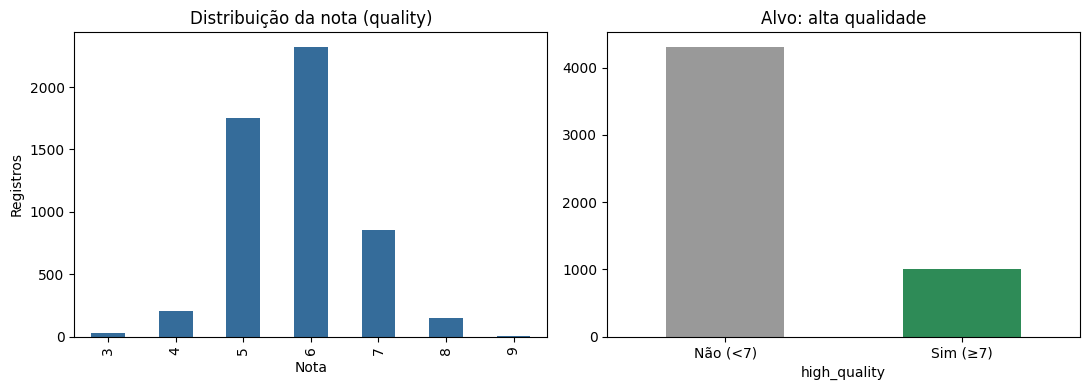

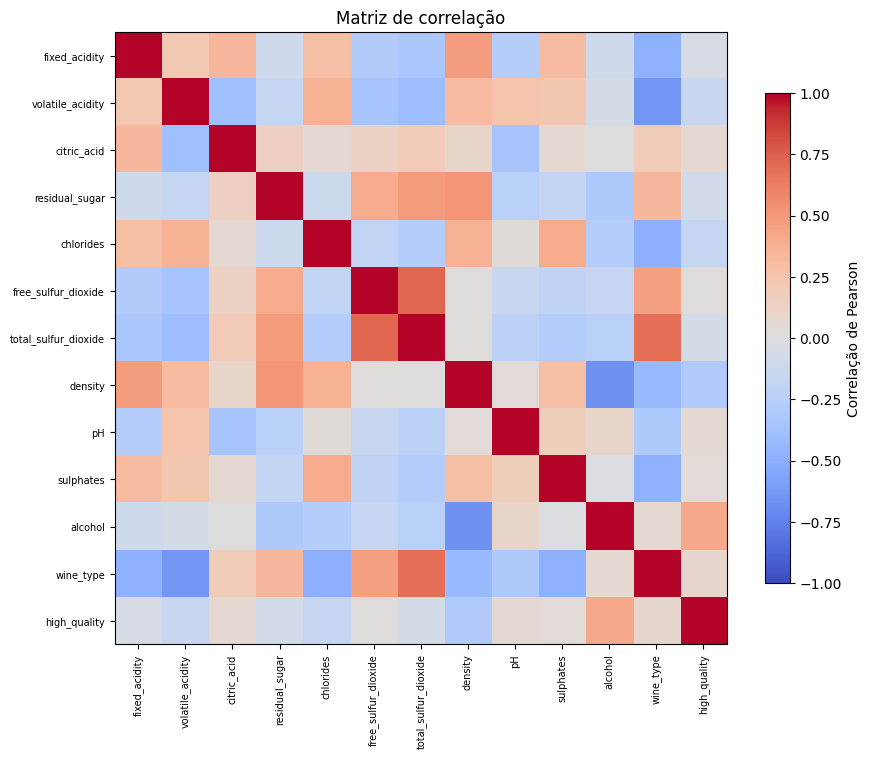

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["quality"].value_counts().sort_index().plot.bar(ax=ax[0], color="#356c9a")
ax[0].set_title("Distribuição da nota (quality)"); ax[0].set_xlabel("Nota"); ax[0].set_ylabel("Registros")
df["high_quality"].value_counts().sort_index().plot.bar(ax=ax[1], color=["#999999", "#2e8b57"])
ax[1].set_xticklabels(["Não (<7)", "Sim (≥7)"], rotation=0); ax[1].set_title("Alvo: alta qualidade")
plt.tight_layout(); plt.savefig(REPORTS / "fig_target.png", dpi=180); plt.show()

corr = df[FEATURES + ["high_quality"]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
fig.colorbar(im, shrink=.8, label="Correlação de Pearson"); ax.set_title("Matriz de correlação")
plt.tight_layout(); plt.savefig(REPORTS / "fig_correlation.png", dpi=180); plt.show()

In [8]:
from sklearn.model_selection import train_test_split
SEED = 42
X, y = df[FEATURES], df["high_quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

# Dados tratados e divisão salvos no Drive (camada "processed")
df.to_csv(PROC / "wine_quality_clean.csv", index=False)
X_train.assign(high_quality=y_train).to_csv(PROC / "train.csv", index=False)
X_test.assign(high_quality=y_test).to_csv(PROC / "test.csv", index=False)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Alta qualidade — treino: %.3f | teste: %.3f" % (y_train.mean(), y_test.mean()))
print(sorted(p.name for p in PROC.iterdir()))

Treino: (4256, 12) | Teste: (1064, 12)
Alta qualidade — treino: 0.190 | teste: 0.190
['test.csv', 'train.csv', 'wine_quality_clean.csv']


## Treinamento e avaliação
Três algoritmos comparados em *pipelines* com padronização (ajustada apenas no treino de cada partição). Hiperparâmetros por `GridSearchCV` com validação cruzada estratificada de 5 partições; métrica de seleção: **F1 da classe positiva** (a classe é minoritária). O teste só é usado na avaliação final.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "LogisticRegression": (
        Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        {"m__C": [0.01, 0.1, 1, 10, 100]}),
    "RandomForest": (
        Pipeline([("sc", StandardScaler()), ("m", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1))]),
        {"m__n_estimators": [200, 400], "m__max_depth": [None, 10, 20], "m__min_samples_leaf": [1, 3]}),
    "GradientBoosting": (
        Pipeline([("sc", StandardScaler()), ("m", GradientBoostingClassifier(random_state=SEED))]),
        {"m__n_estimators": [100, 200], "m__learning_rate": [0.05, 0.1], "m__max_depth": [2, 3]}),
}

searches, cv_rows = {}, []
for name, (pipe, grid) in candidates.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1, refit=True).fit(X_train, y_train)
    searches[name] = gs
    cv_rows.append({"modelo": name, "melhores_parametros": gs.best_params_, "f1_cv_medio": gs.best_score_,
                    "f1_cv_desvio": gs.cv_results_["std_test_score"][gs.best_index_], "tempo_s": round(time.time()-t0, 1)})
    print(f"{name}: F1 CV = {gs.best_score_:.4f} | {gs.best_params_}")
cv_table = pd.DataFrame(cv_rows); display(cv_table)
cv_table.to_csv(REPORTS / "cv_results.csv", index=False)

LogisticRegression: F1 CV = 0.5391 | {'m__C': 0.01}
RandomForest: F1 CV = 0.5579 | {'m__max_depth': 10, 'm__min_samples_leaf': 1, 'm__n_estimators': 400}
GradientBoosting: F1 CV = 0.4631 | {'m__learning_rate': 0.1, 'm__max_depth': 3, 'm__n_estimators': 200}


,modelo,melhores_parametros,f1_cv_medio,f1_cv_desvio,tempo_s
0,LogisticRegression,{'m__C': 0.01},0.539064,0.019904,5.2
1,RandomForest,"{'m__max_depth': 10, 'm__min_samples_leaf': 1,...",0.557898,0.029503,152.7
2,GradientBoosting,"{'m__learning_rate': 0.1, 'm__max_depth': 3, '...",0.463094,0.020253,41.7


,modelo,acuracia,precisao,revocacao,f1,roc_auc,pr_auc
0,LogisticRegression,0.7350,0.4005,0.7970,0.5331,0.8167,0.4736
1,RandomForest,0.8224,0.5259,0.6535,0.5828,0.8636,0.5864
2,GradientBoosting,0.8440,0.6500,0.3861,0.4845,0.8497,0.5585


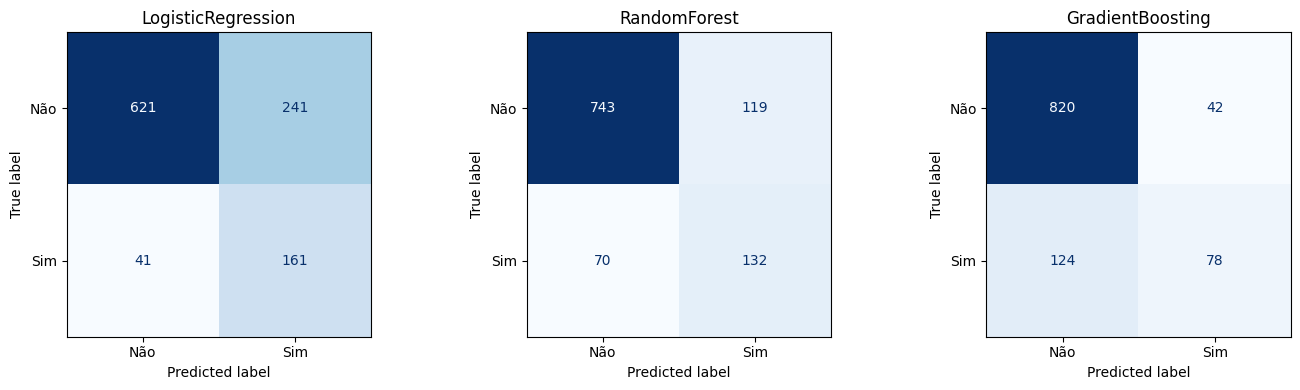

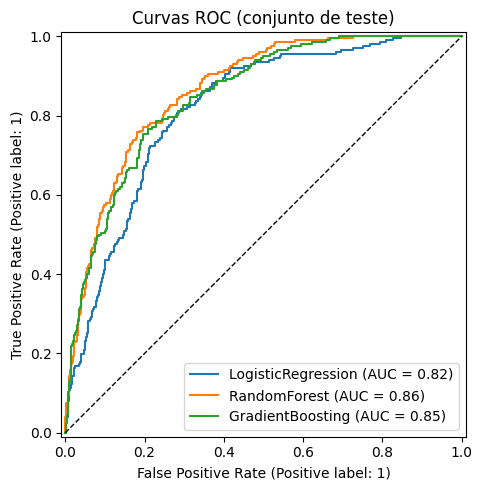

In [10]:
test_rows, proba = [], {}
for name, gs in searches.items():
    p = gs.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int); proba[name] = p
    test_rows.append({"modelo": name, "acuracia": accuracy_score(y_test, pred), "precisao": precision_score(y_test, pred),
                      "revocacao": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
                      "roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p)})
test_table = pd.DataFrame(test_rows).round(4); display(test_table)
test_table.to_csv(REPORTS / "test_results.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (name, gs) in zip(ax, searches.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba[name] >= .5).astype(int)),
                           display_labels=["Não", "Sim"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(name)
plt.tight_layout(); plt.savefig(REPORTS / "fig_confusion.png", dpi=180); plt.show()

fig, a = plt.subplots(figsize=(6, 5))
for name in searches: RocCurveDisplay.from_predictions(y_test, proba[name], name=name, ax=a)
a.plot([0, 1], [0, 1], "k--", lw=1); a.set_title("Curvas ROC (conjunto de teste)")
plt.tight_layout(); plt.savefig(REPORTS / "fig_roc.png", dpi=180); plt.show()

In [11]:
# Seleção pelo critério definido ANTES do teste: maior F1 médio na validação cruzada
best_name = cv_table.sort_values("f1_cv_medio", ascending=False).iloc[0]["modelo"]
best_model = searches[best_name].best_estimator_
print("Modelo selecionado:", best_name)

MODEL_VERSION = "1.0.0"
MODEL_PATH = MODELS / f"wine_model_v{MODEL_VERSION}.joblib"
joblib.dump(best_model, MODEL_PATH)

# Amostra de referência para detecção de drift e estatísticas de treino
X_train.sample(min(1000, len(X_train)), random_state=SEED).to_csv(MODELS / "reference_sample.csv", index=False)

model_card = {
    "modelo": best_name, "versao": MODEL_VERSION, "criado_em_utc": datetime.datetime.utcnow().isoformat(timespec="seconds")+"Z",
    "tarefa": "Classificação binária: alta qualidade (quality >= 7)",
    "dados": {"fonte": "UCI Wine Quality (Cortez et al., 2009)", "hashes_sha256": RAW_HASHES, "linhas_treino": int(len(X_train)), "linhas_teste": int(len(X_test))},
    "atributos": FEATURES, "parametros": searches[best_name].best_params_,
    "metricas_teste": test_table.set_index("modelo").loc[best_name].to_dict(),
    "f1_cv": float(searches[best_name].best_score_), "ambiente": ENV_INFO,
    "uso_pretendido": "Apoio à triagem; decisão final de especialista humano.",
    "limitacoes": ["Nota sensorial é subjetiva", "Base histórica de vinho verde (Portugal)", "Classe positiva minoritária",
                   "Sem validação externa", "Não usar como única base de decisão comercial"],
}
(MODELS / f"model_card_v{MODEL_VERSION}.json").write_text(json.dumps(model_card, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(model_card["metricas_teste"], indent=2))

Modelo selecionado: RandomForest
{
  "acuracia": 0.8224,
  "precisao": 0.5259,
  "revocacao": 0.6535,
  "f1": 0.5828,
  "roc_auc": 0.8636,
  "pr_auc": 0.5864
}


## Implantação em serviço de inferência (FastAPI) e testes
A API é carregada a partir do **modelo salvo no Drive** e executada no próprio Colab (Uvicorn em *thread*). Cada requisição é registrada em `logs/requests.jsonl`, alimentando o monitoramento (Passo 8).

In [12]:
import nest_asyncio, uvicorn
from fastapi import FastAPI, HTTPException, Request
from pydantic import BaseModel, Field
from typing import List
nest_asyncio.apply()

LOG_FILE = LOGS / "requests.jsonl"
service_model = joblib.load(MODEL_PATH)
LOCK = threading.Lock()

class Wine(BaseModel):
    fixed_acidity: float = Field(..., ge=0, le=20)
    volatile_acidity: float = Field(..., ge=0, le=3)
    citric_acid: float = Field(..., ge=0, le=2)
    residual_sugar: float = Field(..., ge=0, le=80)
    chlorides: float = Field(..., ge=0, le=1)
    free_sulfur_dioxide: float = Field(..., ge=0, le=300)
    total_sulfur_dioxide: float = Field(..., ge=0, le=500)
    density: float = Field(..., ge=0.9, le=1.1)
    pH: float = Field(..., ge=2, le=5)
    sulphates: float = Field(..., ge=0, le=3)
    alcohol: float = Field(..., ge=5, le=20)
    wine_type: int = Field(..., ge=0, le=1, description="0 = tinto, 1 = branco")

class Batch(BaseModel):
    items: List[Wine] = Field(..., min_length=1, max_length=500)

app = FastAPI(title="Wine Quality API", version=MODEL_VERSION)

def log(event: dict):
    with LOCK, open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(event, default=str) + "\n")

def _predict(rows: List[Wine]):
    X = pd.DataFrame([r.model_dump() for r in rows])[FEATURES]
    p = service_model.predict_proba(X)[:, 1]
    return X, p

@app.middleware("http")
async def timing(request: Request, call_next):
    t0 = time.perf_counter()
    response = await call_next(request)
    log({"ts": datetime.datetime.utcnow().isoformat(), "evento": "http", "rota": request.url.path,
         "status": response.status_code, "latencia_ms": round((time.perf_counter()-t0)*1000, 2)})
    return response

@app.get("/health")
def health():
    return {"status": "ok", "modelo": best_name, "versao": MODEL_VERSION}

@app.post("/predict")
def predict(w: Wine):
    X, p = _predict([w])
    log({"ts": datetime.datetime.utcnow().isoformat(), "evento": "predicao", "features": X.iloc[0].to_dict(), "prob": float(p[0])})
    return {"alta_qualidade": bool(p[0] >= .5), "probabilidade": round(float(p[0]), 4), "versao_modelo": MODEL_VERSION}

@app.post("/predict_batch")
def predict_batch(b: Batch):
    X, p = _predict(b.items)
    for i in range(len(X)):
        log({"ts": datetime.datetime.utcnow().isoformat(), "evento": "predicao", "features": X.iloc[i].to_dict(), "prob": float(p[i])})
    return {"resultados": [{"alta_qualidade": bool(v >= .5), "probabilidade": round(float(v), 4)} for v in p],
            "versao_modelo": MODEL_VERSION}

config = uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="warning")
server = uvicorn.Server(config)
thread = threading.Thread(target=server.run, daemon=True); thread.start()
time.sleep(3)
import requests
print(requests.get("http://127.0.0.1:8000/health").json())

{'status': 'ok', 'modelo': 'RandomForest', 'versao': '1.0.0'}


In [13]:
URL = "http://127.0.0.1:8000"
test_log = []

# Teste 1: amostra real de cada classe do conjunto de teste
for label in (0, 1):
    row = X_test[y_test == label].iloc[0].to_dict()
    r = requests.post(f"{URL}/predict", json=row)
    test_log.append({"teste": f"predict (classe real {label})", "status": r.status_code, "resposta": r.json()})

# Teste 2: lote com 50 amostras
batch = X_test.head(50).to_dict(orient="records")
r = requests.post(f"{URL}/predict_batch", json={"items": batch})
test_log.append({"teste": "predict_batch (50)", "status": r.status_code, "n_resultados": len(r.json()["resultados"])})

# Teste 3: entrada inválida (pH fora do intervalo) -> deve retornar 422
bad = dict(row); bad["pH"] = 9.9
r = requests.post(f"{URL}/predict", json=bad)
test_log.append({"teste": "entrada inválida", "status": r.status_code, "esperado": 422})

# Teste 4: campo ausente -> 422
bad2 = dict(row); bad2.pop("alcohol")
r = requests.post(f"{URL}/predict", json=bad2)
test_log.append({"teste": "campo ausente", "status": r.status_code, "esperado": 422})

# Teste 5: consistência API x modelo local
api = [x["probabilidade"] for x in requests.post(f"{URL}/predict_batch", json={"items": batch}).json()["resultados"]]
local = service_model.predict_proba(X_test.head(50))[:, 1]
test_log.append({"teste": "consistência API x modelo", "max_diferenca": float(np.max(np.abs(np.array(api) - local))),
                 "ok": bool(np.allclose(api, local, atol=1e-4))})

# Teste 6: latência (100 chamadas unitárias)
lat = []
for i in range(100):
    t0 = time.perf_counter(); requests.post(f"{URL}/predict", json=X_test.iloc[i % len(X_test)].to_dict()); lat.append((time.perf_counter()-t0)*1000)
test_log.append({"teste": "latência 100 chamadas (ms)", "p50": round(np.percentile(lat, 50), 1), "p95": round(np.percentile(lat, 95), 1)})

for t in test_log: print(t)
(EVID / "inference_tests.json").write_text(json.dumps(test_log, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

{'teste': 'predict (classe real 0)', 'status': 200, 'resposta': {'alta_qualidade': False, 'probabilidade': 0.0101, 'versao_modelo': '1.0.0'}}
{'teste': 'predict (classe real 1)', 'status': 200, 'resposta': {'alta_qualidade': True, 'probabilidade': 0.6229, 'versao_modelo': '1.0.0'}}
{'teste': 'predict_batch (50)', 'status': 200, 'n_resultados': 50}
{'teste': 'entrada inválida', 'status': 422, 'esperado': 422}
{'teste': 'campo ausente', 'status': 422, 'esperado': 422}
{'teste': 'consistência API x modelo', 'max_diferenca': 4.9405531786887724e-05, 'ok': True}
{'teste': 'latência 100 chamadas (ms)', 'p50': np.float64(104.3), 'p95': np.float64(213.2)}


814

##Monitoramento

Três dimensões: **operacional** (latência, taxa de erro), **dados** (drift por KS e PSI contra a amostra de treino) e **modelo** (distribuição das probabilidades; desempenho real quando houver rótulos). Para demonstrar o alerta, é simulado um tráfego com deriva (álcool e acidez alterados).

In [14]:
# Simula tráfego com deriva: amostras reais deslocadas (álcool +1,5; acidez volátil +50%; açúcar +40%)
drift = X_test.sample(150, random_state=1).copy()
drift["alcohol"] = (drift["alcohol"] + 1.5).clip(upper=19.5)
drift["volatile_acidity"] = (drift["volatile_acidity"] * 1.5).clip(upper=2.9)
drift["residual_sugar"] = (drift["residual_sugar"] * 1.4).clip(upper=79)
for rec in drift.to_dict(orient="records"):
    requests.post(f"{URL}/predict", json=rec)
print("Tráfego simulado enviado.")

Tráfego simulado enviado.


In [15]:
from scipy.stats import ks_2samp

def read_logs():
    rows = [json.loads(l) for l in open(LOG_FILE, encoding="utf-8")]
    return pd.DataFrame(rows)

def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref); c = np.histogram(cur, edges)[0] / len(cur)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

LIMITES = {"latencia_p95_ms": 500, "taxa_erro": 0.05, "psi_alerta": 0.25, "ks_p_valor": 0.01, "taxa_positiva_min": 0.02, "taxa_positiva_max": 0.60}

logs = read_logs()
http = logs[logs.evento == "http"]; pred = logs[logs.evento == "predicao"].copy()
ref = pd.read_csv(MODELS / "reference_sample.csv")
cur = pd.DataFrame(pred["features"].tolist())

oper = {"requisicoes": int(len(http)), "latencia_p50_ms": float(http.latencia_ms.quantile(.5)),
        "latencia_p95_ms": float(http.latencia_ms.quantile(.95)), "taxa_erro": float((http.status >= 400).mean())}
drift_rows = [{"atributo": f, "psi": psi(ref[f], cur[f]), "ks_p_valor": float(ks_2samp(ref[f], cur[f]).pvalue)} for f in FEATURES if f != "wine_type"]
drift_df = pd.DataFrame(drift_rows).sort_values("psi", ascending=False); display(drift_df.round(4))

taxa_pos = float((pred["prob"] >= .5).mean())
alertas = []
if oper["latencia_p95_ms"] > LIMITES["latencia_p95_ms"]: alertas.append("Latência p95 acima do limite")
if oper["taxa_erro"] > LIMITES["taxa_erro"]: alertas.append(f"Taxa de erro HTTP {oper['taxa_erro']:.1%} acima do limite (inclui testes de entrada inválida)")
for _, r in drift_df.iterrows():
    if r.psi > LIMITES["psi_alerta"] and r.ks_p_valor < LIMITES["ks_p_valor"]: alertas.append(f"Drift em {r.atributo} (PSI={r.psi:.2f})")
if not LIMITES["taxa_positiva_min"] <= taxa_pos <= LIMITES["taxa_positiva_max"]: alertas.append(f"Taxa de predições positivas fora da faixa: {taxa_pos:.1%}")

print(json.dumps(oper, indent=2)); print("Taxa positiva:", round(taxa_pos, 4))
print("\nALERTAS:", *alertas, sep="\n - ") if alertas else print("Sem alertas.")

,atributo,psi,ks_p_valor
10,alcohol,0.3090,0.0000
1,volatile_acidity,0.2495,0.0000
3,residual_sugar,0.1388,0.0640
9,sulphates,0.1222,0.0001
8,pH,0.1186,0.2128
6,total_sulfur_dioxide,0.1073,0.0917
0,fixed_acidity,0.1054,0.0167
7,density,0.0818,0.5360
5,free_sulfur_dioxide,0.0456,0.3271
2,citric_acid,0.0421,0.6254


{
  "requisicoes": 257,
  "latencia_p50_ms": 101.11,
  "latencia_p95_ms": 157.95799999999994,
  "taxa_erro": 0.007782101167315175
}
Taxa positiva: 0.267

ALERTAS:
 - Drift em alcohol (PSI=0.31)


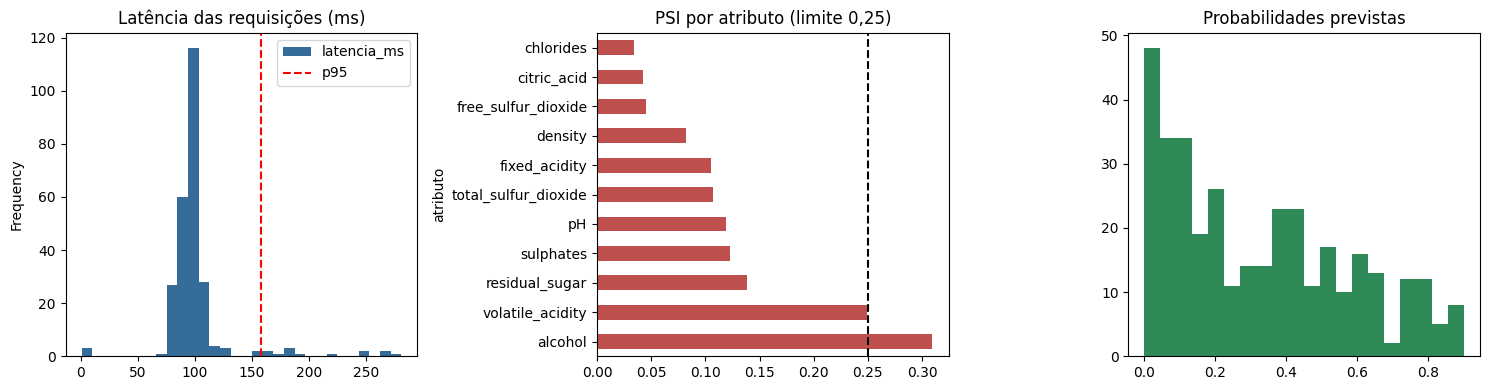

1822

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
http.latencia_ms.plot.hist(bins=30, ax=ax[0], color="#356c9a"); ax[0].axvline(oper["latencia_p95_ms"], color="r", ls="--", label="p95"); ax[0].legend()
ax[0].set_title("Latência das requisições (ms)")
drift_df.set_index("atributo").psi.plot.barh(ax=ax[1], color="#c0504d"); ax[1].axvline(LIMITES["psi_alerta"], color="k", ls="--"); ax[1].set_title("PSI por atributo (limite 0,25)")
ax[2].hist(pred["prob"], bins=20, color="#2e8b57"); ax[2].set_title("Probabilidades previstas")
plt.tight_layout(); plt.savefig(REPORTS / "fig_monitoring.png", dpi=180); plt.show()

monitor_report = {"gerado_em_utc": datetime.datetime.utcnow().isoformat(timespec="seconds")+"Z", "operacional": oper,
                  "taxa_positiva": taxa_pos, "limites": LIMITES, "alertas": alertas, "drift": drift_df.to_dict(orient="records")}
(EVID / "monitoring_report.json").write_text(json.dumps(monitor_report, indent=2, ensure_ascii=False), encoding="utf-8")

## Evidências, governança e encerramento
Consolida artefatos, versões e *hashes* para auditoria. Registre também *prints* da tela (runtime, Drive, saídas de teste e gráficos) para o relatório.

In [17]:
manifest = {}
for p in sorted(BASE.rglob("*")):
    if p.is_file():
        manifest[str(p.relative_to(BASE))] = {"tamanho_bytes": p.stat().st_size, "sha256": sha256(p)}
(EVID / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"{len(manifest)} arquivos registrados.")
for k, v in manifest.items(): print(f"{k:55s} {v['tamanho_bytes']:>10,d} B")

(BASE / ".gitignore").write_text("__pycache__/\n*.pyc\n.ipynb_checkpoints/\ndata/raw/\nlogs/\n.env\n", encoding="utf-8")
(BASE / "README.md").write_text("# Wine Quality – classificação\n\nPipeline em Google Colab. Estrutura: data/, models/, logs/, reports/, evidence/.\n"
                                "Reprodução: executar o notebook; semente 42; versões em evidence/environment.json.\n", encoding="utf-8")
server.should_exit = True
print("Serviço de inferência encerrado.")

20 arquivos registrados.
data/processed/test.csv                                     64,416 B
data/processed/train.csv                                   256,786 B
data/processed/wine_quality_clean.csv                      331,689 B
data/raw/winequality-red.csv                                84,199 B
data/raw/winequality-white.csv                             264,426 B
evidence/data_quality.json                                     348 B
evidence/environment.json                                      313 B
evidence/inference_tests.json                                  817 B
evidence/monitoring_report.json                              1,822 B
logs/requests.jsonl                                        156,869 B
models/model_card_v1.0.0.json                                1,727 B
models/reference_sample.csv                                 58,420 B
models/wine_model_v1.0.0.joblib                         13,548,994 B
reports/cv_results.csv                                         404 B
reports/f